# Assignment 3: Transformer is All You Need

**Task:** Train a small decoder-only Transformer for next-token prediction on Tiny Shakespeare, then visualize its attention and explain its learning behavior.

This notebook implements:

0. Setup and data loading (source, download date, checksum)
1. Data preparation (positional split, subword tokenizer, token windows)
2. A tiny causal Transformer built from basic PyTorch layers, causality checks, and a learning-rate comparison
3. Loss curves, validation perplexity, and attention heatmaps
4. A comparison table, positional-encoding and runtime measurements, and a discussion


## 0. Setup

Import the libraries used below and fix the constants that make the work reproducible. Hardware and package versions are recorded because training time and exact losses depend on them; every configuration is trained in the same runtime so their times are comparable.


In [1]:
import hashlib
import os
import platform
import random
import subprocess
import sys
from datetime import date
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib
import numpy as np
import pandas as pd
import torch

try:
    import tokenizers
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tokenizers"])
    import tokenizers

assert hasattr(torch.nn, "RMSNorm"), "PyTorch >= 2.4 is required for nn.RMSNorm"
assert tuple(int(part) for part in tokenizers.__version__.split(".")[:2]) >= (0, 20), (
    f"tokenizers {tokenizers.__version__} is too old; run `pip install -U 'tokenizers>=0.20'` and restart the runtime"
)

SEED = 42
TRAIN_FRACTION = 0.8
ARTIFACTS_DIR = Path("artifacts")  # tokenizer and selected checkpoint
ASSETS_DIR = Path("assets")  # figures used in the report
ARTIFACTS_DIR.mkdir(exist_ok=True)
ASSETS_DIR.mkdir(exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def cpu_model():
    if platform.system() == "Linux":
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    if platform.system() == "Darwin":
        result = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True)
        return result.stdout.strip()
    return platform.processor() or "unknown"


set_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Python      {platform.python_version()}")
print(f"PyTorch     {torch.__version__}")
print(f"tokenizers  {tokenizers.__version__}")
print(f"NumPy       {np.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"pandas      {pd.__version__}")
print(f"Platform    {platform.platform()}")
print(f"CPU         {cpu_model()} ({os.cpu_count()} cores)")
if DEVICE.type == "cuda":
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU         {gpu.name} ({gpu.total_memory / 1024**3:.1f} GB)")
print(f"Device      {DEVICE}")
print(f"Seed        {SEED}")


Python      3.13.16
PyTorch     2.14.1+cu130
tokenizers  0.23.3
NumPy       2.4.6
matplotlib  3.10.0
pandas      2.2.3
Platform    Linux-6.6.159+-x86_64-with-glibc2.39
CPU         Intel(R) Xeon(R) CPU @ 2.00GHz (2 cores)
GPU         Tesla T4 (14.6 GB)
Device      cuda
Seed        42


### 0.1 Load the data

Prefer a local `input.txt` in the notebook working directory (Colab upload). If it is missing, download it from the source, Andrej Karpathy's char-rnn repository; the download is checksum-verified before it replaces `input.txt`, and its date is saved next to the file so reruns report the original date. For an uploaded file, `UPLOADED_COPY_DATE` gives the download date (2026-11-21 for the repository copy, `None` if unknown). The SHA-256 check guarantees that every run and every experiment uses exactly the same text.


In [2]:
DATA_FILE = Path("input.txt")
DATE_FILE = Path("input.txt.date")  # download date of DATA_FILE
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
EXPECTED_SHA256 = "86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed"
# Download date of an uploaded input.txt: the repository copy was fetched on 2026-11-21.
# Set to None for a copy from elsewhere whose download date is unknown.
UPLOADED_COPY_DATE = "2026-11-21"

if not DATA_FILE.exists():
    temp_file = DATA_FILE.with_suffix(".download")
    try:
        urlretrieve(DATA_URL, temp_file)
        downloaded_sha256 = hashlib.sha256(temp_file.read_bytes()).hexdigest()
        if downloaded_sha256 != EXPECTED_SHA256:
            raise RuntimeError(f"Downloaded file has unexpected SHA-256 {downloaded_sha256}")
        DATE_FILE.write_text(date.today().isoformat())
        temp_file.replace(DATA_FILE)
    finally:
        temp_file.unlink(missing_ok=True)

if DATE_FILE.exists():
    download_date = DATE_FILE.read_text().strip()
else:
    download_date = UPLOADED_COPY_DATE or "unknown"

raw_bytes = DATA_FILE.read_bytes()
sha256 = hashlib.sha256(raw_bytes).hexdigest()
assert sha256 == EXPECTED_SHA256, f"Unexpected file contents (SHA-256 {sha256})"
text = raw_bytes.decode("utf-8")
chars = sorted(set(text))

print(f"Source         {DATA_URL}")
print(f"Download date  {download_date}")
print(f"SHA-256        {sha256}")
print(f"Characters     {len(text):,}")
print(f"Lines          {text.count(chr(10)):,}")
print(f"Unique chars   {len(chars)}: {repr(''.join(chars))}")
print(f"Spaces         {text.count(' '):,} ({text.count(' ') / len(text):.1%} of characters)")
print()
print(text[:250])


Source         https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Download date  2026-11-21
SHA-256        86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed
Characters     1,115,394
Lines          40,000
Unique chars   65: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
Spaces         169,892 (15.2% of characters)

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



**Interpretation.**

- The file matches the expected checksum: 1,115,394 characters in 40,000 lines, so every experiment below uses identical text.
- Only 65 distinct characters occur: the 52 upper- and lower-case letters, space, newline, the digit `3`, and ten punctuation marks. Spaces alone are about 15% of the text.
- The corpus is play dialogue: a speaker name on its own line ending in a colon, followed by the speech. Newlines, colons, and capitalized names are therefore frequent structural patterns that the tokenizer and model must represent.


## 1. Data preparation

The raw text is split by position before the tokenizer is fitted or any window is created, so nothing derived from validation text can influence training.


### 1.1 Positional split

The first 80% of characters is used for training and the final 20% for validation. A positional cut keeps validation text contiguous and later in the file, so the model is scored on passages it never saw rather than on shuffled lines from the same scenes.


In [3]:
split_at = int(TRAIN_FRACTION * len(text))
train_text = text[:split_at]
val_text = text[split_at:]

print(f"Split at character  {split_at:,}")
print(f"Train characters    {len(train_text):,}")
print(f"Val characters      {len(val_text):,}")
print(f"Validation characters missing from training: {sorted(set(val_text) - set(train_text))}")
print()
print(f"Before the cut: {text[split_at - 60:split_at]!r}")
print(f"After the cut:  {text[split_at:split_at + 60]!r}")


Split at character  892,315
Train characters    892,315
Val characters      223,079
Validation characters missing from training: []

Before the cut: 'ur frames,--let me be bold;\nI do arrest your words. Be that '
After the cut:  "you are,\nThat is, a woman; if you be more, you're none;\nIf y"


**Interpretation.**

- Training text is 892,315 characters and validation text is 223,079 characters.
- The cut falls mid-sentence ("Be that | you are"). This is harmless: the two halves are tokenized and windowed separately, so no window contains text from both sides.
- Every validation character also occurs in training text, so the tokenizer below never needs its unknown token on this data.


### 1.2 Subword tokenizer

A character-level BPE tokenizer (Hugging Face `tokenizers`) is fitted on `train_text` only:

- **Base alphabet:** the 65 characters of the training text. BPE then repeatedly merges the most frequent adjacent pair until the vocabulary reaches 500 entries, including the single special token `[UNK]`.
- **Pre-tokenization:** each newline is isolated as its own token, and spaces become the visible marker `▁` attached to the following word (as in SentencePiece). Merges therefore never span a space or a line break (punctuation can still join a word, as in `GLOUCESTER:`), and decoding restores the exact text.
- **Unseen symbols:** a character absent from the training text maps to `[UNK]`. It still occupies one position, so the sequence length is unchanged, but its identity is lost.
- **Why not byte-level BPE:** a byte-level tokenizer never needs `[UNK]`, but its 256 base bytes would use half of the 500-entry budget; the character alphabet leaves 434 entries for merges and so produces shorter sequences.

The fitted tokenizer is saved to `artifacts/` and reused unchanged for validation and for every configuration.


In [4]:
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers

VOCAB_SIZE = 500  # includes the special token
UNK_TOKEN = "[UNK]"

tokenizer = Tokenizer(models.BPE(unk_token=UNK_TOKEN))
tokenizer.pre_tokenizer = pre_tokenizers.Sequence([
    pre_tokenizers.Split("\n", behavior="isolated"),
    pre_tokenizers.Metaspace(prepend_scheme="never"),
])
tokenizer.decoder = decoders.Metaspace(prepend_scheme="never")
trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=[UNK_TOKEN], show_progress=False)
tokenizer.train_from_iterator([train_text], trainer=trainer)
tokenizer.save(str(ARTIFACTS_DIR / "tokenizer.json"))

vocab_size = tokenizer.get_vocab_size()
unk_id = tokenizer.token_to_id(UNK_TOKEN)
assert vocab_size <= VOCAB_SIZE

train_encoding = tokenizer.encode(train_text)
val_encoding = tokenizer.encode(val_text)
assert tokenizer.decode(train_encoding.ids) == train_text
assert tokenizer.decode(val_encoding.ids) == val_text

print(f"Vocabulary size     {vocab_size} (1 special + {len(set(train_text))} characters + {vocab_size - 1 - len(set(train_text))} merges)")
for name, chars, ids in [("Train", train_text, train_encoding.ids), ("Val", val_text, val_encoding.ids)]:
    print(f"{name:<5} tokens        {len(ids):,} ({len(chars) / len(ids):.2f} characters per token, {ids.count(unk_id)} [UNK])")
print()
longest = sorted(tokenizer.get_vocab(), key=lambda token: (-len(token), token))[:10]
print(f"Longest tokens:     {longest}")
print(f"Example:            {tokenizer.encode('First Citizen:' + chr(10) + 'Before we proceed').tokens}")
print(f"Unseen characters:  {tokenizer.encode('café ☃').tokens}")


Vocabulary size     500 (1 special + 65 characters + 434 merges)
Train tokens        407,182 (2.19 characters per token, 0 [UNK])
Val   tokens        105,963 (2.11 characters per token, 0 [UNK])

Longest tokens:     ['GLOUCESTER:', '▁RICHARD', 'GLOUCES', '▁father', '▁should', 'ICHARD', '▁again', '▁blood', '▁death', '▁heart']
Example:            ['First', '▁C', 'it', 'i', 'z', 'en', ':', '\n', 'B', 'e', 'fore', '▁we', '▁pro', 'ce', 'ed']
Unseen characters:  ['c', 'a', 'f', '[UNK]', '▁', '[UNK]']


**Interpretation.**

- The vocabulary is exactly 500 entries: `[UNK]`, the 65 training characters, and 434 learned merges.
- Encoding and decoding reproduce both splits exactly, and neither split contains `[UNK]`.
- Training text averages about 2.2 characters per token and validation text slightly fewer. The merges were learned from training text, so they fit it a little better.
- The longest merges are frequent whole words (`▁father`, `▁blood`) and speaker names (`GLOUCESTER:`). Rare words split into short pieces; for example, `Citizen` becomes `▁C it i z en`.
- The unseen characters in `café ☃` become `[UNK]`, which is how the tokenizer handles symbols missing from the training text.


### 1.3 Token windows

Each split is encoded separately and cut into windows of `N + 1 = 65` tokens. For a window `z`, the input is `z[0:N]` and the target is `z[1:N+1]`, so the target at position `i` is the token that follows input position `i`. The same `N = 64` is used for every configuration.

- **Training windows** start at random offsets, so they may overlap and every training token except the first can appear as a target.
- **Validation windows** start at `0, N, 2N, …`; consecutive windows share one boundary token, so each target position is scored exactly once. The final short window is **dropped**, so the loss needs no padding mask.


In [5]:
CONTEXT_LEN = 64  # N

train_ids = torch.tensor(train_encoding.ids, dtype=torch.long)
val_ids = torch.tensor(val_encoding.ids, dtype=torch.long)


def get_train_batch(batch_size, generator):
    """Sample random, possibly overlapping training windows: inputs and targets of shape (B, N)."""
    starts = torch.randint(0, len(train_ids) - CONTEXT_LEN, (batch_size,), generator=generator)
    windows = torch.stack([train_ids[s:s + CONTEXT_LEN + 1] for s in starts.tolist()])
    return windows[:, :-1], windows[:, 1:]


num_val_windows = (len(val_ids) - 1) // CONTEXT_LEN
val_windows = torch.stack([val_ids[i * CONTEXT_LEN:i * CONTEXT_LEN + CONTEXT_LEN + 1] for i in range(num_val_windows)])
val_x, val_y = val_windows[:, :-1], val_windows[:, 1:]
num_val_targets = val_y.numel()

# Each validation target is the next unscored token: positions 1 .. num_val_targets, each once.
assert torch.equal(val_y.reshape(-1), val_ids[1:num_val_targets + 1])
assert torch.equal(val_x[:, 1:], val_y[:, :-1])

print(f"Train tokens                   {len(train_ids):,}")
print(f"Val tokens                     {len(val_ids):,}")
print(f"Validation windows             {num_val_windows:,} x {CONTEXT_LEN} targets")
print(f"Evaluated validation targets   {num_val_targets:,}")
print(f"Dropped (final short window)   {len(val_ids) - 1 - num_val_targets} targets")

x, y = get_train_batch(4, torch.Generator().manual_seed(SEED))
print(f"\nTraining batch shapes: inputs {tuple(x.shape)}, targets {tuple(y.shape)}")
print("First 8 positions of one training window:")
for position in range(8):
    print(f"  input {tokenizer.id_to_token(x[0, position].item())!r:>12}  ->  target {tokenizer.id_to_token(y[0, position].item())!r}")


Train tokens                   407,182
Val tokens                     105,963
Validation windows             1,655 x 64 targets
Evaluated validation targets   105,920
Dropped (final short window)   42 targets

Training batch shapes: inputs (4, 64), targets (4, 64)
First 8 positions of one training window:
  input         'ur'  ->  target 'n'
  input          'n'  ->  target ','
  input          ','  ->  target '▁good'
  input      '▁good'  ->  target '▁C'
  input         '▁C'  ->  target 'at'
  input         'at'  ->  target 'es'
  input         'es'  ->  target 'b'
  input          'b'  ->  target 'y,'


**Interpretation.**

- Training text yields 407,182 tokens. Validation yields 105,963 tokens, cut into 1,655 windows of 64 targets each.
- **105,920 validation targets** are scored. The final short window would have held 42 targets and is dropped; the first validation token is never a target because it has no preceding context.
- The assertions confirm that each validation target is scored once, and that each target row is its input row shifted one token to the left.
- The printed pairs show the shift directly: each target is the next input token.


## 2. Tiny decoder-only Transformer

The model is built from basic layers only (`nn.Embedding`, `nn.Linear`, `nn.RMSNorm`); attention is written with tensor operations. It is checked for causality, then trained in three configurations that differ only in learning rate.


### 2.1 Model

Shapes use `B` = batch size, `T` = sequence length (at most `N = 64`), `D = 128` hidden size, `H = 4` heads of size `D / H = 32`, and `V = 500` vocabulary entries.

- **Input:** token embeddings `(B, T, D)` plus fixed sinusoidal positional encodings `(T, D)`. Attention by itself treats its inputs as an unordered set, so the encodings give an explicit absolute-position signal. (The causal mask also gives each position a different prefix, so order is not entirely invisible without them.)
- **Causal self-attention:** linear projections give queries, keys, and values, reshaped to `(B, H, T, 32)`. Scores `Q Kᵀ / √32` have shape `(B, H, T, T)` with query rows and key columns. Entries with key `j > i` are set to `-inf` **before** the softmax over keys, so their probabilities are exactly zero. The heads are concatenated back to `(B, T, D)` and passed through an output projection.
- **Block (×2):** pre-norm residual layout, `x + Attention(RMSNorm(x))` followed by `x + FFN(RMSNorm(x))`; the feed-forward network is `Linear(128 → 512) → GELU → Linear(512 → 128)`.
- **Output:** a final RMSNorm and a linear projection to raw logits `(B, T, V)`.
- **Dropout:** 0.1 on the embeddings, on the attention probabilities, and on each residual branch; it is inactive in `eval()` mode.

Each attention layer keeps its probabilities after the softmax and before dropout, so they can be plotted in Step 3.


In [6]:
import copy
import json
import math
import time

import torch.nn as nn
import torch.nn.functional as F

D_MODEL = 128
N_HEADS = 4
N_LAYERS = 2
FFN_DIM = 4 * D_MODEL
DROPOUT = 0.1


def sinusoidal_encoding(length, dim):
    """Fixed positional encodings (length, dim): sine on even features, cosine on odd features."""
    position = torch.arange(length).unsqueeze(1)
    frequency = torch.exp(-math.log(10000.0) * torch.arange(0, dim, 2) / dim)
    encoding = torch.zeros(length, dim)
    encoding[:, 0::2] = torch.sin(position * frequency)
    encoding[:, 1::2] = torch.cos(position * frequency)
    return encoding


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, context_len, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.query = nn.Linear(d_model, d_model)
        self.key = nn.Linear(d_model, d_model)
        self.value = nn.Linear(d_model, d_model)
        self.out = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len, dtype=torch.bool)))
        self.attn_probs = None  # (B, H, T, T) after softmax, before dropout

    def split_heads(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)  # (B, H, T, head_dim)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.split_heads(self.query(x)), self.split_heads(self.key(x)), self.split_heads(self.value(x))
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)  # (B, H, T, T): query rows, key columns
        scores = scores.masked_fill(~self.causal_mask[:T, :T], float("-inf"))
        probs = scores.softmax(dim=-1)
        self.attn_probs = probs.detach()
        context = self.attn_dropout(probs) @ v  # (B, H, T, head_dim)
        context = context.transpose(1, 2).reshape(B, T, D)  # concatenate heads
        return self.out(context)


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, context_len, dropout):
        super().__init__()
        self.attn_norm = nn.RMSNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, context_len, dropout)
        self.ffn_norm = nn.RMSNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, ffn_dim), nn.GELU(), nn.Linear(ffn_dim, d_model))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.dropout(self.attn(self.attn_norm(x)))
        x = x + self.dropout(self.ffn(self.ffn_norm(x)))
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, context_len, d_model, n_heads, n_layers, ffn_dim, dropout):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.register_buffer("positional_encoding", sinusoidal_encoding(context_len, d_model))
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            [TransformerBlock(d_model, n_heads, ffn_dim, context_len, dropout) for _ in range(n_layers)]
        )
        self.final_norm = nn.RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        """Token IDs (B, T) -> raw logits (B, T, vocab_size)."""
        x = self.dropout(self.token_embedding(idx) + self.positional_encoding[:idx.shape[1]])
        for block in self.blocks:
            x = block(x)
        return self.lm_head(self.final_norm(x))

    def attention_maps(self):
        """Attention probabilities of the last forward pass, one (B, H, T, T) tensor per layer."""
        return [block.attn.attn_probs for block in self.blocks]


def build_model():
    return TinyTransformer(vocab_size, CONTEXT_LEN, D_MODEL, N_HEADS, N_LAYERS, FFN_DIM, DROPOUT)


In [7]:
set_seed(SEED)
model = build_model().to(DEVICE)
num_params = sum(p.numel() for p in model.parameters())
parts = {
    "Token embedding": model.token_embedding,
    "Transformer blocks": model.blocks,
    "Final RMSNorm + output projection": nn.ModuleList([model.final_norm, model.lm_head]),
}
print(f"Parameters  {num_params:,}")
for name, part in parts.items():
    print(f"  {name:<36}{sum(p.numel() for p in part.parameters()):>9,}")

x, y = get_train_batch(4, torch.Generator().manual_seed(SEED))
x, y = x.to(DEVICE), y.to(DEVICE)
model.eval()
with torch.no_grad():
    logits = model(x)
    initial_loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1)).item()
print(f"\nInput {tuple(x.shape)} -> logits {tuple(logits.shape)}")
print(f"Attention per layer {tuple(model.attention_maps()[0].shape)}")
print(f"Loss before training {initial_loss:.3f} (uniform guess: ln {vocab_size} = {math.log(vocab_size):.3f})")


Parameters  524,660
  Token embedding                        64,000
  Transformer blocks                    396,032
  Final RMSNorm + output projection      64,628

Input (4, 64) -> logits (4, 64, 500)
Attention per layer (4, 4, 64, 64)
Loss before training 6.352 (uniform guess: ln 500 = 6.215)


**Interpretation.**

- The model has 524,660 parameters. The two blocks hold 396,032 of them; the embedding and the output projection hold about 64,000 each.
- The shapes match the design: inputs `(4, 64)` produce logits `(4, 64, 500)`, and each layer stores attention probabilities of shape `(4, 4, 64, 64)` (batch, head, query, key).
- Before training, the loss is 6.352, close to `ln 500 ≈ 6.21`, the loss of a uniform guess over the vocabulary. This is the expected starting point for random weights; a single mean loss does not show that every individual prediction is close to uniform.


### 2.2 Causality checks

Both checks run in `eval()` mode, so dropout cannot hide or create differences:

1. **Future attention is zero:** in every layer and head, all probabilities above the diagonal (key `j > i`) must be exactly `0`, and each row must sum to `1`.
2. **Future tokens cannot change earlier outputs:** replace the second half of a validation sequence with random tokens; logits at earlier positions must not change, while later logits should.

As a separate correctness check, the first layer's attention output is compared with PyTorch's `F.scaled_dot_product_attention` using the same weights, inputs, and causal mask, with dropout off. The reference function is used only for this comparison, not in the model.


In [8]:
def causality_checks(model):
    model.eval()
    sequence = val_x[:1].to(DEVICE)  # first validation window, (1, N)
    split = CONTEXT_LEN // 2
    changed = sequence.clone()
    changed[:, split:] = torch.randint(0, vocab_size, (1, CONTEXT_LEN - split), generator=torch.Generator().manual_seed(SEED)).to(DEVICE)

    with torch.no_grad():
        block = model.blocks[0]
        hidden = block.attn_norm(model.token_embedding(sequence) + model.positional_encoding[:CONTEXT_LEN])
        ours = block.attn(hidden)
        attn = block.attn
        q, k, v = attn.split_heads(attn.query(hidden)), attn.split_heads(attn.key(hidden)), attn.split_heads(attn.value(hidden))
        reference = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=0.0)
        reference = attn.out(reference.transpose(1, 2).reshape(hidden.shape))
        reference_diff = (ours - reference).abs().max().item()

        changed_logits = model(changed)
        logits = model(sequence)  # last forward, so attention_maps() holds every layer's maps for `sequence`
        maps = model.attention_maps()
        future = torch.triu(torch.ones(CONTEXT_LEN, CONTEXT_LEN, dtype=torch.bool, device=DEVICE), diagonal=1)
        max_future_weight = max(m[..., future].abs().max().item() for m in maps)
        max_row_sum_error = max((m.sum(dim=-1) - 1).abs().max().item() for m in maps)
        earlier_change = (logits[:, :split] - changed_logits[:, :split]).abs().max().item()
        later_change = (logits[:, split:] - changed_logits[:, split:]).abs().max().item()

    print(f"Max attention weight on future keys        {max_future_weight:.1e}")
    print(f"Max |row sum - 1|                          {max_row_sum_error:.1e}")
    print(f"Max logit change, positions 0-{split - 1} (unchanged) {earlier_change:.1e}")
    print(f"Max logit change, positions {split}-{CONTEXT_LEN - 1} (changed)  {later_change:.3f}")
    print(f"Max difference from reference attention    {reference_diff:.1e}")
    assert max_future_weight == 0.0
    assert max_row_sum_error < 1e-5
    assert earlier_change < 1e-5 and later_change > 1e-3
    assert reference_diff < 1e-5


causality_checks(model)


Max attention weight on future keys        0.0e+00
Max |row sum - 1|                          1.2e-07
Max logit change, positions 0-31 (unchanged) 0.0e+00
Max logit change, positions 32-63 (changed)  3.025
Max difference from reference attention    1.5e-07


**Interpretation.**

- Every attention weight on a future key is exactly `0`: the `-inf` scores become zero probabilities after the softmax, and each row still sums to `1`.
- Replacing tokens 32–63 leaves the logits at positions 0–31 unchanged (differences at floating-point noise level at most), while later logits change. Each prediction therefore depends only on its own and earlier tokens.
- The hand-written attention matches PyTorch's reference implementation to floating-point precision, so the projections, scaling, masking, softmax, and head concatenation are computed correctly.


### 2.3 Training setup

- **Loss:** `cross_entropy` on raw logits and the shifted target IDs. Logits `(B, N, V)` are flattened to `(B·N, V)` and targets `(B, N)` to `(B·N)`; no softmax is applied before the loss, because `cross_entropy` applies log-softmax itself.
- **Optimizer:** AdamW (weight decay 0.01), batch size 64, constant learning rate, gradient-norm clipping at 1.0, and a fixed budget of **5,000 steps** per configuration.
- **Controlled change: learning rate.** The baseline uses `1e-3`; the two other configurations use `3e-4` and `3e-3`. The split, tokenizer, context length, model size, seed, batch order, and step budget are identical, so differences between runs come from the learning rate alone.
- **Validation:** every 100 steps (and before training) the model is scored on all 105,920 validation targets in `eval()` mode under `torch.no_grad()`; validation loss is total negative log-likelihood divided by the number of targets.
- **Checkpoint selection:** each configuration keeps the weights from its lowest-validation-loss evaluation. The configuration with the lowest of these is the selected checkpoint, saved to `artifacts/` with the tokenizer.
- **Training time** counts only the optimization steps; validation passes and checkpoint copies are timed separately.


In [9]:
BATCH_SIZE = 64
MAX_STEPS = 5000
EVAL_EVERY = 100
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0
CONFIGS = {"lr 3e-4": 3e-4, "lr 1e-3 (baseline)": 1e-3, "lr 3e-3": 3e-3}

val_x_device, val_y_device = val_x.to(DEVICE), val_y.to(DEVICE)


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


@torch.no_grad()
def evaluate(model, batch_size=256):
    """Validation cross-entropy: total NLL over all evaluated targets / number of targets."""
    model.eval()
    total_nll = 0.0
    for i in range(0, len(val_x_device), batch_size):
        logits = model(val_x_device[i:i + batch_size])
        targets = val_y_device[i:i + batch_size]
        total_nll += F.cross_entropy(logits.reshape(-1, vocab_size), targets.reshape(-1), reduction="sum").item()
    return total_nll / num_val_targets


def train_config(learning_rate):
    set_seed(SEED)  # identical initial weights and dropout masks for every configuration
    model = build_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=WEIGHT_DECAY)
    batch_generator = torch.Generator().manual_seed(SEED)  # identical batch order for every configuration

    eval_start = time.perf_counter()
    history = {"train_step": [], "train_loss": [], "val_step": [0], "val_loss": [evaluate(model)]}
    initial_eval_seconds = time.perf_counter() - eval_start
    best = {"val_loss": history["val_loss"][0], "step": 0, "state_dict": copy.deepcopy(model.state_dict())}
    periodic_eval_seconds = 0.0  # validation and checkpoint copies inside the training loop
    sync()
    start = time.perf_counter()
    for step in range(1, MAX_STEPS + 1):
        model.train()
        x, y = get_train_batch(BATCH_SIZE, batch_generator)
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        history["train_step"].append(step)
        history["train_loss"].append(loss.item())

        if step % EVAL_EVERY == 0:
            eval_start = time.perf_counter()
            val_loss = evaluate(model)
            history["val_step"].append(step)
            history["val_loss"].append(val_loss)
            if val_loss < best["val_loss"]:
                best = {"val_loss": val_loss, "step": step, "state_dict": copy.deepcopy(model.state_dict())}
            periodic_eval_seconds += time.perf_counter() - eval_start
    sync()
    total_seconds = time.perf_counter() - start
    return {
        "learning_rate": learning_rate,
        "history": history,
        "best": best,
        "train_seconds": total_seconds - periodic_eval_seconds,
        "eval_seconds": initial_eval_seconds + periodic_eval_seconds,
    }


### 2.4 Train the configurations


In [10]:
results = {}
for name, learning_rate in CONFIGS.items():
    results[name] = train_config(learning_rate)
    result = results[name]
    print(
        f"{name:<20} best val loss {result['best']['val_loss']:.4f} at step {result['best']['step']:>4}"
        f" | final val loss {result['history']['val_loss'][-1]:.4f}"
        f" | training {result['train_seconds']:.0f} s, validation {result['eval_seconds']:.0f} s"
    )


lr 3e-4              best val loss 3.4827 at step 4600 | final val loss 3.4881 | training 48 s, validation 3 s
lr 1e-3 (baseline)   best val loss 3.3808 at step 4300 | final val loss 3.3943 | training 46 s, validation 3 s
lr 3e-3              best val loss 3.3632 at step 4300 | final val loss 3.3798 | training 47 s, validation 3 s


**Interpretation.**

- All three runs start from the same weights and see the same batches, so the learning rate is the only difference between them.
- Within the 5,000-step budget, a higher learning rate gives a lower best validation loss: 3.483 for `3e-4`, 3.381 for the baseline `1e-3`, and 3.363 for `3e-3`. The gain from `1e-3` to `3e-3` (0.018) is much smaller than the gain from `3e-4` to `1e-3` (0.102).
- Every run reaches its best validation loss before the last step (steps 4,300–4,600) and ends slightly above it. Step 3 compares this with the training-loss curves.
- Training took 46–48 s per configuration on the Tesla T4 (`cuda`). Every configuration does the same computation per step, so the few-second spread reflects variation in the shared Colab runtime, not the learning rate.


### 2.5 Selected checkpoint and run record

The checkpoint with the lowest validation cross-entropy across all configurations is saved with its configuration, and the causality checks are repeated on the trained weights.


In [11]:
selected_name = min(results, key=lambda name: results[name]["best"]["val_loss"])
selected = results[selected_name]
selected_model = build_model().to(DEVICE)
selected_model.load_state_dict(selected["best"]["state_dict"])
assert abs(evaluate(selected_model) - selected["best"]["val_loss"]) < 1e-4

torch.save(
    {
        "config": selected_name,
        "learning_rate": selected["learning_rate"],
        "step": selected["best"]["step"],
        "val_loss": selected["best"]["val_loss"],
        "model_args": dict(vocab_size=vocab_size, context_len=CONTEXT_LEN, d_model=D_MODEL, n_heads=N_HEADS,
                           n_layers=N_LAYERS, ffn_dim=FFN_DIM, dropout=DROPOUT),
        "state_dict": {key: value.detach().cpu() for key, value in selected["best"]["state_dict"].items()},
    },
    ARTIFACTS_DIR / "selected_checkpoint.pt",
)
(ARTIFACTS_DIR / "training_histories.json").write_text(
    json.dumps({name: result["history"] for name, result in results.items()})
)

hardware = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else cpu_model()
print(f"Selected checkpoint  {selected_name}, step {selected['best']['step']}, val loss {selected['best']['val_loss']:.4f}")
print(f"Optimizer            AdamW (weight decay {WEIGHT_DECAY}), gradient clipping {GRAD_CLIP}")
print(f"Batch size           {BATCH_SIZE} windows x {CONTEXT_LEN} tokens")
print(f"Steps                {MAX_STEPS:,} per configuration (validation every {EVAL_EVERY})")
print(f"Parameters           {num_params:,}")
print(f"Hardware             {hardware} ({DEVICE.type})")
print(f"Packages             PyTorch {torch.__version__}, tokenizers {tokenizers.__version__}, Python {platform.python_version()}")
print(f"Seed                 {SEED}")
print()
causality_checks(selected_model)


Selected checkpoint  lr 3e-3, step 4300, val loss 3.3632
Optimizer            AdamW (weight decay 0.01), gradient clipping 1.0
Batch size           64 windows x 64 tokens
Steps                5,000 per configuration (validation every 100)
Parameters           524,660
Hardware             Tesla T4 (cuda)
Packages             PyTorch 2.14.1+cu130, tokenizers 0.23.3, Python 3.13.16
Seed                 42

Max attention weight on future keys        0.0e+00
Max |row sum - 1|                          2.4e-07
Max logit change, positions 0-31 (unchanged) 0.0e+00
Max logit change, positions 32-63 (changed)  19.321
Max difference from reference attention    9.5e-07


**Interpretation.**

- The selected checkpoint is the `3e-3` configuration at its lowest-validation-loss step; re-evaluating the saved weights reproduces the recorded loss.
- The causality checks pass on the trained weights as well, so causality is enforced by the mask and does not depend on the weights.
- The printed record lists everything the handout requires for each configuration (optimizer, batch size, learning rate, steps, parameter count, hardware, package versions, seed); training times are in the table above.


## 3. Training curves, perplexity, and attention

All evaluation runs in `model.eval()` under `torch.no_grad()`, on the same 105,920 validation targets for every configuration.


### 3.1 Loss curves

The two curves measure different things:

- **Training cross-entropy** is the loss of each single mini-batch of 64 random windows, in training mode with dropout active. It is noisy, so a 100-step moving average is drawn over it.
- **Validation cross-entropy** is the loss over all 105,920 validation targets, in evaluation mode without dropout, every 100 steps.

The y-axis is cut at 4.6 so the later differences stay visible; every run starts near 6.35 and falls below 4.6 within the first few hundred steps. The dashed line marks each run's best validation step, which is the checkpoint kept.


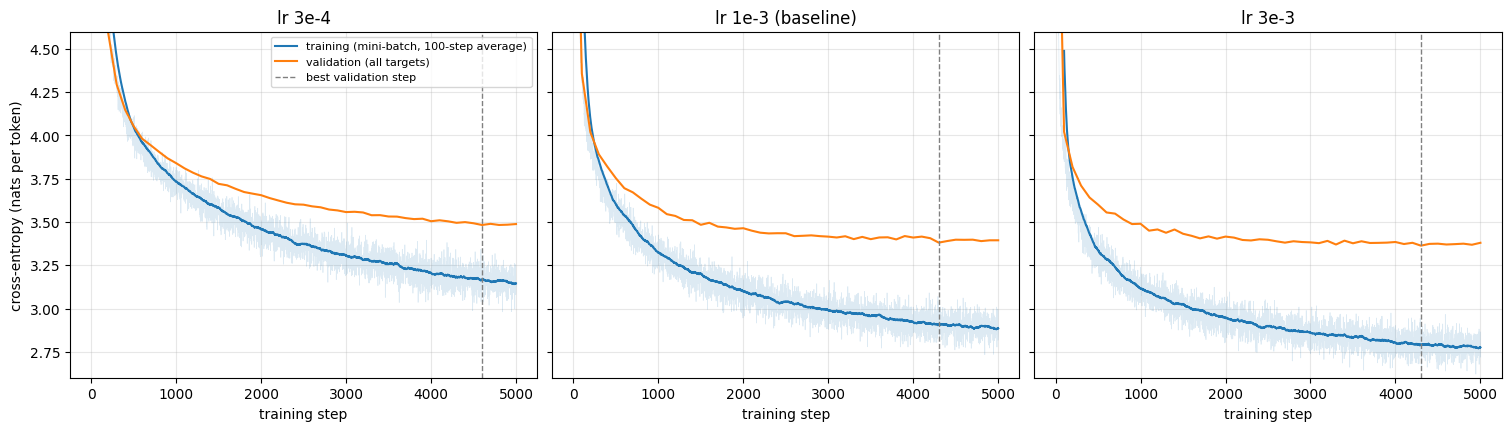

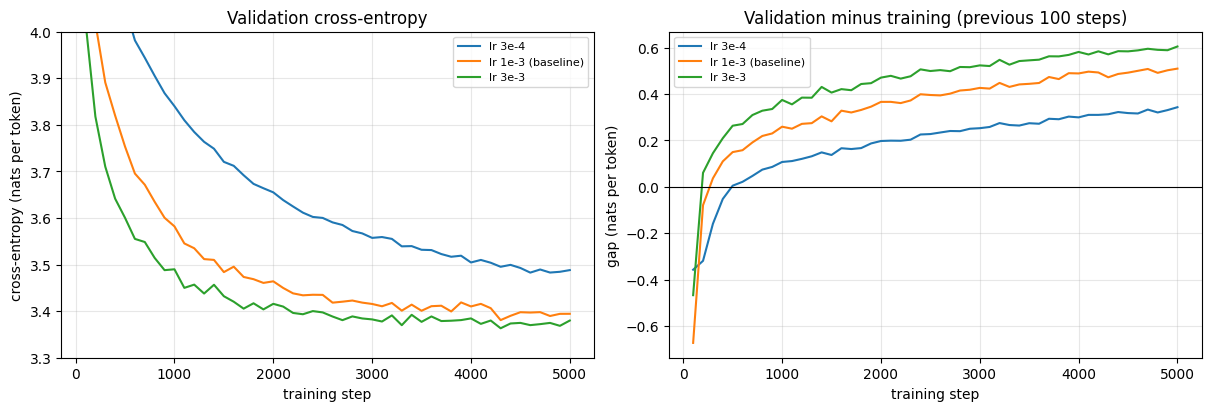

Configuration        Best step  Best val  Final val  Final train  Final gap
lr 3e-4                   4600    3.4827     3.4881       3.1449     0.3432
lr 1e-3 (baseline)        4300    3.3808     3.3943       2.8848     0.5095
lr 3e-3                   4300    3.3632     3.3798       2.7749     0.6050


In [12]:
import matplotlib.pyplot as plt

SMOOTH = 100


def moving_average(values, window):
    return np.convolve(values, np.ones(window) / window, mode="valid")


def train_average(history, step, window=EVAL_EVERY):
    """Mean mini-batch training loss over the `window` steps ending at `step`."""
    return float(np.mean(history["train_loss"][step - window:step]))


fig, axes = plt.subplots(1, len(results), figsize=(15, 4.2), sharey=True, layout="constrained")
for ax, (name, result) in zip(axes, results.items()):
    history = result["history"]
    ax.plot(history["train_step"], history["train_loss"], color="tab:blue", alpha=0.15, linewidth=0.5)
    ax.plot(history["train_step"][SMOOTH - 1:], moving_average(history["train_loss"], SMOOTH),
            color="tab:blue", label=f"training (mini-batch, {SMOOTH}-step average)")
    ax.plot(history["val_step"], history["val_loss"], color="tab:orange", label="validation (all targets)")
    ax.axvline(result["best"]["step"], color="gray", linestyle="--", linewidth=1, label="best validation step")
    ax.set_title(name)
    ax.set_xlabel("training step")
    ax.set_ylim(2.6, 4.6)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("cross-entropy (nats per token)")
axes[0].legend(loc="upper right", fontsize=8)
fig.savefig(ASSETS_DIR / "loss_curves.png", dpi=150)
plt.show()

fig, (ax_val, ax_gap) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for name, result in results.items():
    history = result["history"]
    steps = history["val_step"][1:]
    ax_val.plot(steps, history["val_loss"][1:], label=name)
    ax_gap.plot(steps, [val - train_average(history, step) for step, val in zip(steps, history["val_loss"][1:])], label=name)
ax_val.set(title="Validation cross-entropy", xlabel="training step", ylabel="cross-entropy (nats per token)", ylim=(3.3, 4.0))
ax_gap.set(title="Validation minus training (previous 100 steps)", xlabel="training step", ylabel="gap (nats per token)")
ax_gap.axhline(0, color="black", linewidth=0.8)
for ax in (ax_val, ax_gap):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.savefig(ASSETS_DIR / "validation_and_gap.png", dpi=150)
plt.show()

print(f"{'Configuration':<20}{'Best step':>10}{'Best val':>10}{'Final val':>11}{'Final train':>13}{'Final gap':>11}")
for name, result in results.items():
    history = result["history"]
    final_train = train_average(history, MAX_STEPS)
    print(f"{name:<20}{result['best']['step']:>10}{result['best']['val_loss']:>10.4f}{history['val_loss'][-1]:>11.4f}"
          f"{final_train:>13.4f}{history['val_loss'][-1] - final_train:>11.4f}")


**Interpretation.**

- All runs fall fast in the first ~500 steps and slowly afterwards. A higher learning rate descends faster: validation loss first reaches 3.5 at step 4,300 with `3e-4`, step 1,500 with `1e-3`, and step 900 with `3e-3`.
- In the first few hundred steps validation loss is *below* the training average, because that average still includes earlier, worse batches and training mode adds dropout. After that the gap opens and keeps widening: by step 5,000 it is 0.34 nats for `3e-4`, 0.51 for `1e-3`, and 0.61 for `3e-3`.
- Between steps 3,000 and 5,000, validation loss improves by only 0.021 for `1e-3` and 0.002 for `3e-3` while training loss keeps falling. Most of the remaining training progress is fitting the training text rather than generalizing, which is the onset of overfitting. Both runs reach their lowest validation loss at step 4,300 and end slightly higher, so the selected checkpoints are not the final weights. `3e-4` is still improving (by 0.069 over the same steps, best at step 4,600) and has not converged within the budget.
- No run is unstable: between evaluations, validation loss rises by at most 0.022 nats for `3e-3`, 0.019 for `1e-3`, and 0.007 for `3e-4`. The higher learning rates are only slightly less smooth.


### 3.2 Validation loss and perplexity

Each configuration's selected checkpoint is re-scored on the validation windows. Validation loss is the total negative log-likelihood divided by the number of scored targets, and `PPL = exp(validation loss)`; batch perplexities are never averaged. Perplexity is per BPE token, so these values are comparable only with each other (same tokenizer, validation tokens, and windows). For scale, a uniform guess over the 500-entry vocabulary has PPL 500.


In [13]:
print(f"{'Configuration':<20}{'Best step':>10}{'Val loss':>10}{'PPL':>8}")
for name, result in results.items():
    checkpoint_model = build_model().to(DEVICE)
    checkpoint_model.load_state_dict(result["best"]["state_dict"])
    result["val_loss"] = evaluate(checkpoint_model)
    result["ppl"] = math.exp(result["val_loss"])
    print(f"{name:<20}{result['best']['step']:>10}{result['val_loss']:>10.4f}{result['ppl']:>8.2f}")
print(f"\nScored validation targets {num_val_targets:,}")


Configuration        Best step  Val loss     PPL
lr 3e-4                   4600    3.4827   32.55
lr 1e-3 (baseline)        4300    3.3808   29.39
lr 3e-3                   4300    3.3632   28.88

Scored validation targets 105,920


**Interpretation.**

- The re-scored checkpoints reproduce the best validation losses recorded during training, so the saved weights are the ones selected.
- Validation perplexity is 32.6 for `3e-4`, 29.4 for the baseline `1e-3`, and 28.9 for `3e-3`. Each next BPE token is, on average, as uncertain as a uniform choice among about 29–33 tokens, compared with 500 for a uniform guess over the vocabulary.
- The ordering matches validation loss because `PPL = exp(loss)` is monotonic; a 0.02 nat difference in loss is about a 2% difference in perplexity.


### 3.3 Attention heatmaps

All maps use one fixed validation sequence: the first 32 tokens of validation window 3, which contain a speaker line. Because of the causal mask, these 32 rows are identical whether the model sees 32 or all 64 tokens of the window.

- Rows are **queries** (the token doing the attending) and columns are **keys** (the tokens attended to); axis labels are the actual tokens, with `▁` marking a preceding space and `\n` a newline.
- Values are probabilities after the softmax and before dropout, on a fixed 0–1 color scale. Grey cells are future keys removed by the causal mask.
- The first two figures show all four heads of each layer for the selected checkpoint. The third compares one head before training and at the selected checkpoint, with the same sequence and color scale.


Sequence: 'el, if you give me love.\n\nISABELLA:\nI know your virtue hath a licen'


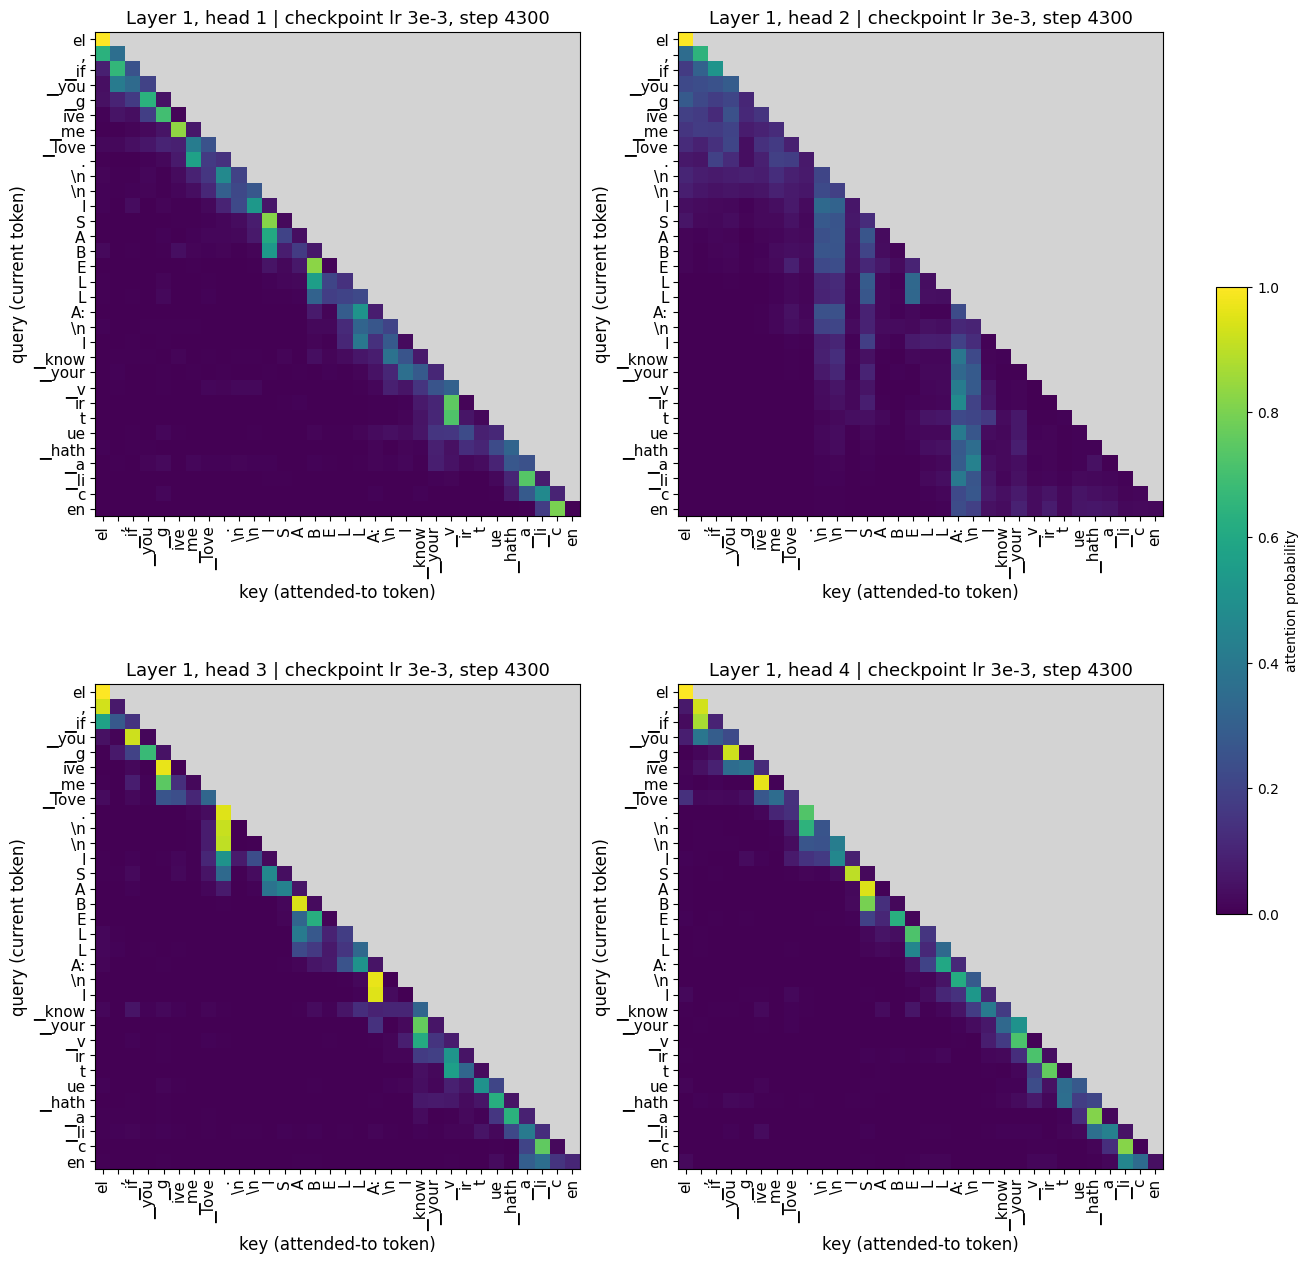

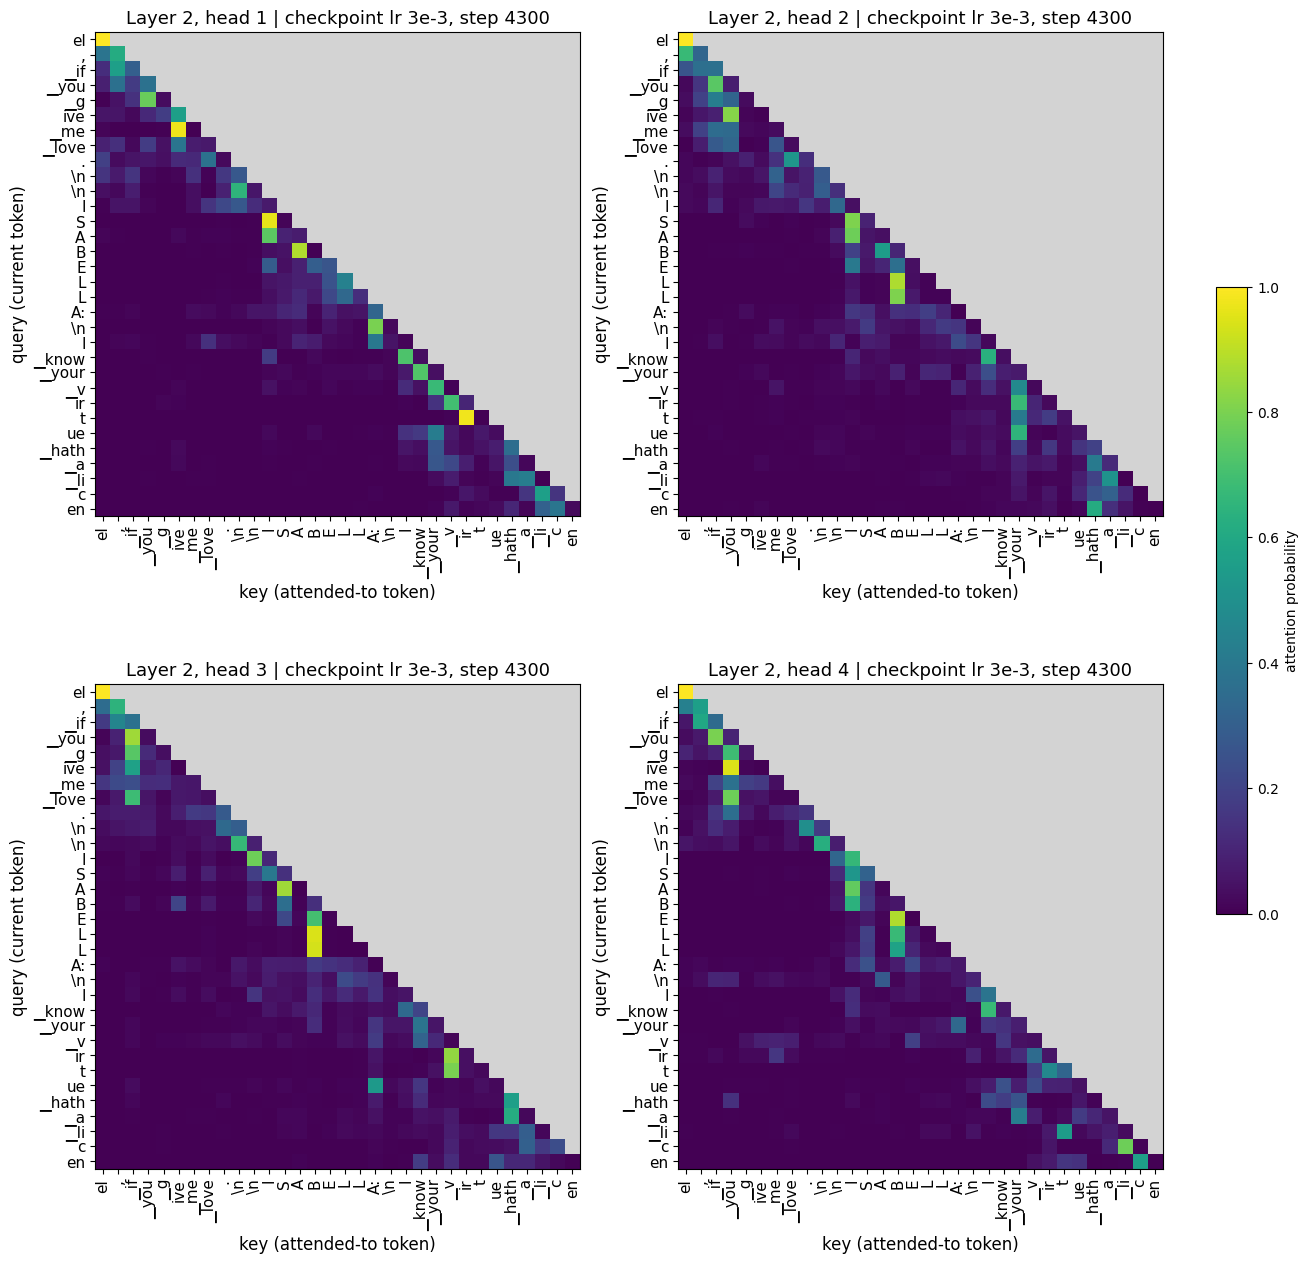

In [14]:
HEATMAP_WINDOW = 3
SHOW = 32

heatmap_ids = val_x[HEATMAP_WINDOW:HEATMAP_WINDOW + 1].to(DEVICE)
labels = [tokenizer.id_to_token(t).replace("\n", "\\n") for t in heatmap_ids[0, :SHOW].tolist()]
future_mask = np.triu(np.ones((SHOW, SHOW), dtype=bool), k=1)
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgrey")


def attention_for(model):
    """Per-layer (H, SHOW, SHOW) attention probabilities for the heatmap sequence."""
    model.eval()
    with torch.no_grad():
        model(heatmap_ids)
    return [maps[0, :, :SHOW, :SHOW].cpu().numpy() for maps in model.attention_maps()]


def draw(ax, probs, title):
    image = ax.imshow(np.ma.masked_array(probs, future_mask), cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(SHOW), labels, rotation=90, fontsize=11)
    ax.set_yticks(range(SHOW), labels, fontsize=11)
    ax.set_xlabel("key (attended-to token)", fontsize=12)
    ax.set_ylabel("query (current token)", fontsize=12)
    ax.set_title(title, fontsize=13)
    return image


print(f"Sequence: {tokenizer.decode(heatmap_ids[0, :SHOW].tolist())!r}")
checkpoint_label = f"checkpoint {selected_name}, step {selected['best']['step']}"
selected_maps = attention_for(selected_model)
for layer in range(N_LAYERS):
    fig, axes = plt.subplots(2, 2, figsize=(13, 13), layout="constrained")
    for head, ax in enumerate(axes.flat):
        image = draw(ax, selected_maps[layer][head], f"Layer {layer + 1}, head {head + 1} | {checkpoint_label}")
    fig.colorbar(image, ax=axes, shrink=0.5, label="attention probability")
    fig.savefig(ASSETS_DIR / f"attention_layer{layer + 1}.png", dpi=150)
    plt.show()


One sequence can be unrepresentative, so the next cell summarizes every head over all 1,655 validation windows, using query positions 16–63 so that each query has at least 16 keys to choose from:

- **previous / self / first:** mean probability on key `i − 1`, on key `i`, and on key `0`;
- **distance:** mean `i − j` weighted by attention, i.e. how far back the head looks on average;
- **entropy:** spread of the attention distribution in nats. Uniform attention over the available keys would give about 3.6 here, and attention on a single key gives 0.


In [15]:
@torch.no_grad()
def head_statistics(model, start=16):
    """Mean attention statistics per (layer, head) over all validation windows and query positions >= start."""
    model.eval()
    query = torch.arange(start, CONTEXT_LEN, device=DEVICE)
    distance = (query.view(-1, 1) - torch.arange(CONTEXT_LEN, device=DEVICE).view(1, -1)).clamp(min=0).float()
    totals = torch.zeros(N_LAYERS, N_HEADS, 5, device=DEVICE)
    for i in range(0, len(val_x_device), 256):
        model(val_x_device[i:i + 256])
        for layer, probs in enumerate(model.attention_maps()):
            p = probs[:, :, start:, :]  # (B, H, queries, keys)
            per_query = torch.stack([
                probs[:, :, query, query - 1],
                probs[:, :, query, query],
                p[..., 0],
                (p * distance).sum(-1),
                -(p * p.clamp_min(1e-12).log()).sum(-1),
            ], dim=-1)  # (B, H, queries, 5)
            totals[layer] += per_query.sum(dim=(0, 2))
    return (totals / (len(val_x_device) * len(query))).cpu()


stats = head_statistics(selected_model)
print(f"{'Layer':>5}{'Head':>5}{'previous':>10}{'self':>7}{'first':>7}{'distance':>10}{'entropy':>9}")
for layer in range(N_LAYERS):
    for head in range(N_HEADS):
        previous, own, first, distance, entropy = stats[layer, head].tolist()
        print(f"{layer + 1:>5}{head + 1:>5}{previous:>10.2f}{own:>7.2f}{first:>7.2f}{distance:>10.1f}{entropy:>9.2f}")
uniform = np.mean([math.log(i + 1) for i in range(16, CONTEXT_LEN)])
print(f"\nUniform attention entropy over the same positions: {uniform:.2f}")


Layer Head  previous   self  first  distance  entropy
    1    1      0.40   0.10   0.00       3.7     1.63
    1    2      0.06   0.04   0.00       7.3     2.06
    1    3      0.51   0.10   0.00       2.3     1.03
    1    4      0.54   0.13   0.00       2.8     1.27
    2    1      0.30   0.08   0.00       5.8     1.81
    2    2      0.17   0.06   0.00       6.7     2.17
    2    3      0.23   0.07   0.00       6.2     2.13
    2    4      0.29   0.08   0.00       6.2     1.95

Uniform attention entropy over the same positions: 3.64


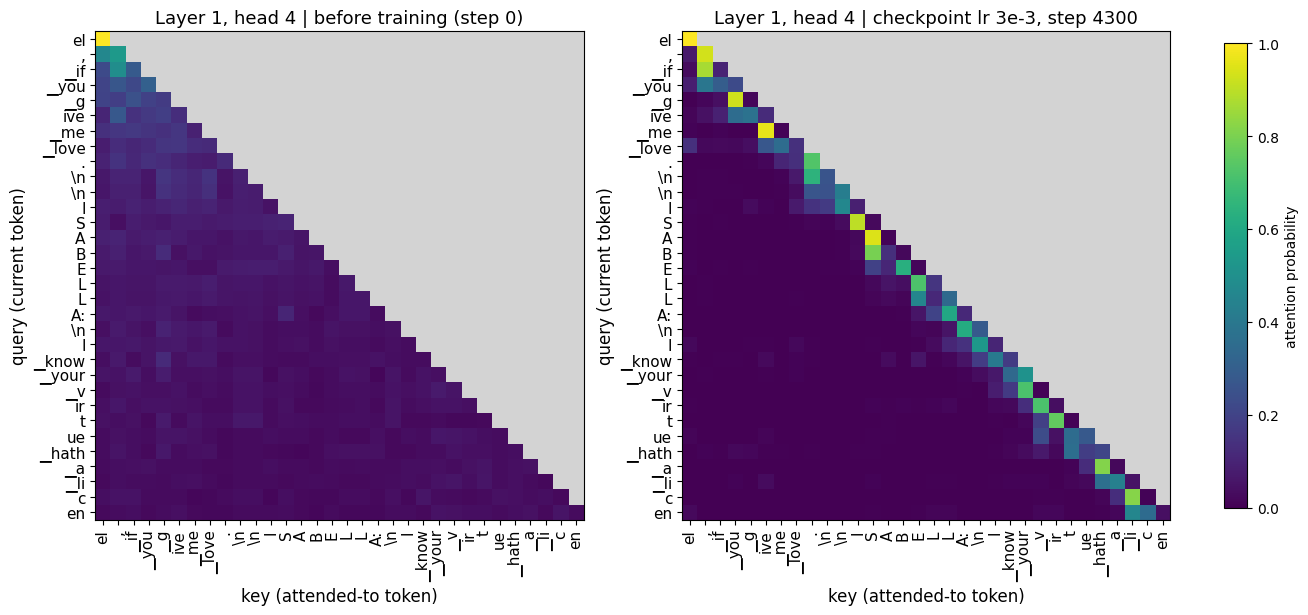

In [16]:
compare_layer = 0
compare_head = int(stats[compare_layer, :, 0].argmax())  # layer-1 head with the most previous-token attention

set_seed(SEED)
untrained_model = build_model().to(DEVICE)  # the step-0 weights shared by every configuration
untrained_maps = attention_for(untrained_model)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.8), layout="constrained")
title = f"Layer {compare_layer + 1}, head {compare_head + 1}"
draw(axes[0], untrained_maps[compare_layer][compare_head], f"{title} | before training (step 0)")
image = draw(axes[1], selected_maps[compare_layer][compare_head], f"{title} | {checkpoint_label}")
fig.colorbar(image, ax=axes, shrink=0.7, label="attention probability")
fig.savefig(ASSETS_DIR / "attention_before_after.png", dpi=150)
plt.show()


**Interpretation.** Attention weights show how this computation mixes earlier tokens; a bright cell does not by itself show that the token caused the prediction or that the model "understands" it.

- **Causal boundary.** Every cell above the diagonal is grey: no query attends to a later token. The first query (`el`) has only itself to attend to, so its row is a single cell with probability 1; the second row splits between two keys. The before/after figure shows that this boundary is fixed by the mask, while the pattern *below* it is learned.
- **Previous-token heads in layer 1.** Heads 1, 3, and 4 put most of their weight on the immediately preceding token, visible as a bright line just below the diagonal (for example, each letter of `I S A B E L L A:` attends to the letter before it). Over all validation windows these heads give 0.40–0.54 of their attention to the previous token, against 0.06 for head 2. Before training, the layer-1 head with the most previous-token attention spreads its attention almost evenly over the past; after training it is sharp. In head 3, the line breaks attend back to the punctuation that ended the line (`.` and `A:`) rather than to the newline itself.
- **Line-structure and longer-range heads.** Layer 1, head 2 is the broadest layer-1 head (entropy 2.06 nats, mean distance 7.3 tokens). On this sequence, the queries of the line after the speaker name (`▁know`, `▁your`, `▁v`, …) attend strongly to the `A:` token that ends `ISABELLA:`. Layer-2 heads look further back on average (mean distance 5.8–6.7 tokens) and often attend to an earlier piece of the same word: in layer 2, head 2, the letters `S` and `A` attend mostly to the name's first letter `I`, and the pieces `▁v`, `ir`, `t`, and `ue` attend back to `▁your`; in heads 2 and 3, the later letters `E`, `L`, `L` attend to `B`.
- No head behaves like an attention "sink" on the first token: beyond position 16, every head gives it almost no weight.


## 4. Comparison of configurations and discussion

The three configurations differ only in learning rate; the split, tokenizer, context length, model, seed, batch order, and 5,000-step budget are identical, and all are scored on the same 105,920 validation targets.


### 4.1 Comparison table


In [17]:
comparison = pd.DataFrame([
    {
        "Configuration": name,
        "Learning rate": result["learning_rate"],
        "Parameters": num_params,
        "Training time (s)": round(result["train_seconds"], 1),
        "Best step": result["best"]["step"],
        "Best val loss": round(result["val_loss"], 4),
        "PPL": round(result["ppl"], 2),
        "Final val loss": round(result["history"]["val_loss"][-1], 4),
        "Final gap": round(result["history"]["val_loss"][-1] - train_average(result["history"], MAX_STEPS), 3),
    }
    for name, result in results.items()
]).set_index("Configuration")
(ARTIFACTS_DIR / "comparison.json").write_text(comparison.reset_index().to_json(orient="records", indent=1))

hardware = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else cpu_model()
print(f"Shared settings: AdamW (weight decay {WEIGHT_DECAY}), batch {BATCH_SIZE}, {MAX_STEPS:,} steps, N = {CONTEXT_LEN}, "
      f"seed {SEED}, {hardware} ({DEVICE.type})")
comparison


Shared settings: AdamW (weight decay 0.01), batch 64, 5,000 steps, N = 64, seed 42, Tesla T4 (cuda)


,Learning rate,Parameters,Training time (s),Best step,Best val loss,PPL,Final val loss,Final gap
Configuration,,,,,,,,
lr 3e-4,0.0003,524660,48.0,4600,3.4827,32.55,3.4881,0.343
lr 1e-3 (baseline),0.0010,524660,45.6,4300,3.3808,29.39,3.3943,0.510
lr 3e-3,0.0030,524660,46.7,4300,3.3632,28.88,3.3798,0.605


**Interpretation.**

- All three configurations have the same 524,660 parameters and the same work per step, so their training times (45.6–48.0 s on the T4) differ only by a few seconds of runtime variation; the measured step time in Section 4.3 (10.4 ms, about 52 s for 5,000 steps) gives the cost of one step.
- **Effect of the controlled change.** Raising the learning rate from `3e-4` to `1e-3` lowers the best validation loss by 0.102 (PPL 32.6 → 29.4); raising it again to `3e-3` lowers it by only 0.018 (PPL 29.4 → 28.9). Returns diminish quickly.
- A higher learning rate also fits the training text faster: the final train–validation gap grows from 0.34 to 0.51 to 0.61 nats, and the `3e-3` validation loss has flattened by step 3,000 (Section 3.1). Within this budget, the fastest learner is also the most overfit, yet it still has the best validation loss.
- `3e-4` reaches its best at step 4,600, near the end of the budget, and has not converged; with more steps its ranking could change. The other two reach their best at step 4,300 and end slightly higher.


### 4.2 What the positional encoding contributes

The causality checks in Section 2.2 already show what masking does: it removes every path from future tokens to earlier predictions. To measure how much the trained model *uses* the positional encoding, the selected checkpoint is scored again with the sinusoidal encodings set to zero (no retraining). Two references put the numbers in context:

- a **unigram baseline** that ignores context and predicts every target from training-set token frequencies (add-one smoothing);
- the **selected model** with its positional encodings intact.

Removing the encodings is an input the model never saw during training, so part of any increase reflects that mismatch rather than lost order information alone.


In [18]:
@torch.no_grad()
def evaluate_without_positions(model):
    saved = model.positional_encoding.clone()
    model.positional_encoding.zero_()
    try:
        return evaluate(model)
    finally:
        model.positional_encoding.copy_(saved)


counts = torch.bincount(train_ids, minlength=vocab_size).double() + 1
unigram_log_probs = (counts / counts.sum()).log()
unigram_loss = -unigram_log_probs[val_y.reshape(-1)].mean().item()
selected_loss = evaluate(selected_model)
no_position_loss = evaluate_without_positions(selected_model)
assert abs(evaluate(selected_model) - selected_loss) < 1e-6  # encodings restored

print(f"{'Model':<42}{'Val loss':>9}{'PPL':>9}")
for label, loss in [
    ("Unigram baseline (no context)", unigram_loss),
    (f"Selected checkpoint, positions removed", no_position_loss),
    (f"Selected checkpoint ({selected_name})", selected_loss),
]:
    print(f"{label:<42}{loss:>9.4f}{math.exp(loss):>9.2f}")


Model                                      Val loss      PPL
Unigram baseline (no context)                5.5311   252.42
Selected checkpoint, positions removed       4.5038    90.36
Selected checkpoint (lr 3e-3)                3.3632    28.88


**Interpretation.**

- A context-free baseline that predicts every token from its add-one-smoothed training frequency scores 5.53 (PPL 252). The trained model reaches 3.36 (PPL 28.9), 2.17 nats better than this baseline.
- With its positional encodings removed, the same model scores 4.50 (PPL 90.4): it keeps only about 47% of its improvement over the unigram baseline. The trained model therefore relies heavily on the explicit position signal. This is consistent with the previous-token heads in Section 3.3, which must know where position `i − 1` is.
- The model without encodings is still much better than the unigram baseline, so the identity of the earlier tokens remains useful even when their order is not given explicitly (the causal mask still gives each position a different set of visible tokens).
- Part of the drop comes from evaluating on inputs unlike those seen in training, so this measures how much *this* model depends on the encodings, not how well a model trained without them would do.


### 4.3 Runtime and memory

The cell below times the parts of one training step on a fresh model with the same settings, and estimates the largest memory items from tensor shapes. The step benchmark reuses one batch already on the device and, like the training loop, includes the forward pass, backward pass, gradient clipping, AdamW update, and reading the loss; batch sampling and validation are timed separately. Validation time comes from the training runs above.


In [19]:
def seconds_per_call(fn, repeats=50, warmup=5):
    for _ in range(warmup):
        fn()
    sync()
    start = time.perf_counter()
    for _ in range(repeats):
        fn()
    sync()
    return (time.perf_counter() - start) / repeats


set_seed(SEED)
profile_model = build_model().to(DEVICE)
profile_optimizer = torch.optim.AdamW(profile_model.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)
profile_generator = torch.Generator().manual_seed(SEED)
profile_x, profile_y = (t.to(DEVICE) for t in get_train_batch(BATCH_SIZE, profile_generator))


def training_step():
    profile_model.train()
    loss = F.cross_entropy(profile_model(profile_x).reshape(-1, vocab_size), profile_y.reshape(-1))
    profile_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(profile_model.parameters(), GRAD_CLIP)
    profile_optimizer.step()
    return loss.item()


def forward_only():
    profile_model.eval()
    with torch.no_grad():
        profile_model(profile_x)


batch_seconds = seconds_per_call(lambda: get_train_batch(BATCH_SIZE, profile_generator), repeats=200)
step_seconds = seconds_per_call(training_step)
forward_seconds = seconds_per_call(forward_only)
validation_seconds = seconds_per_call(lambda: evaluate(profile_model), repeats=3, warmup=1)
train_total = sum(result["train_seconds"] for result in results.values())
eval_total = sum(result["eval_seconds"] for result in results.values())

print(f"{'Batch sampling (CPU)':<42}{batch_seconds * 1e3:8.2f} ms")
print(f"{'Training step (fixed batch on device)':<42}{step_seconds * 1e3:8.2f} ms "
      f"({BATCH_SIZE * CONTEXT_LEN / step_seconds:,.0f} tokens/s)")
print(f"{'Forward pass only (eval)':<42}{forward_seconds * 1e3:8.2f} ms")
print(f"{f'Full validation pass ({num_val_windows:,} windows)':<42}{validation_seconds:8.2f} s")
print(f"{'Validation share of run time':<42}{eval_total / (train_total + eval_total):8.1%}")

MB = 1024 ** 2
float_bytes = 4
print()
print(f"{'Parameters + gradients + AdamW state':<42}{4 * num_params * float_bytes / MB:8.1f} MB")
print(f"{'Attention probabilities per layer':<42}{BATCH_SIZE * N_HEADS * CONTEXT_LEN ** 2 * float_bytes / MB:8.1f} MB (B x H x N x N)")
print(f"{'Output logits':<42}{BATCH_SIZE * CONTEXT_LEN * vocab_size * float_bytes / MB:8.1f} MB (B x N x V)")
if DEVICE.type == "cuda":
    baseline = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    training_step()
    peak = torch.cuda.max_memory_allocated()
    print(f"{'GPU memory in use before the step':<42}{baseline / MB:8.1f} MB (all tensors held by the notebook)")
    print(f"{'Peak GPU memory during the step':<42}{peak / MB:8.1f} MB (+{(peak - baseline) / MB:.1f} MB for the step)")


Batch sampling (CPU)                          0.26 ms
Training step (fixed batch on device)        10.35 ms (395,645 tokens/s)
Forward pass only (eval)                      2.58 ms
Full validation pass (1,655 windows)          0.07 s
Validation share of run time                  6.3%

Parameters + gradients + AdamW state           8.0 MB
Attention probabilities per layer              4.0 MB (B x H x N x N)
Output logits                                  7.8 MB (B x N x V)
GPU memory in use before the step             86.3 MB (all tensors held by the notebook)
Peak GPU memory during the step              184.7 MB (+98.3 MB for the step)


**Interpretation.**

- One training step on a fixed batch of 64 × 64 tokens takes about 10.4 ms on the Tesla T4 (about 396,000 tokens per second), so 5,000 steps cost under a minute per configuration, matching the measured training times. Sampling a batch on the CPU takes 0.26 ms, so data loading is not a bottleneck.
- A full validation pass over all 1,655 windows takes about 0.07 s; evaluating every 100 steps adds about 6% to the run time. Evaluating every step would cost far more than training itself.
- Individual tensors are small: the parameters, gradients, and AdamW state take 8 MB. The peak during a training step is larger, because the backward pass also stores intermediate values (feed-forward activations, attention scores, softmax outputs), but it stays small: the notebook already holds 86 MB of GPU tensors, and a training step raises the peak to 185 MB (+98 MB), a tiny fraction of the T4's 14.6 GB. Of the estimated tensors, the largest are the output logits (`B × N × V`, 7.8 MB), which at `N = 64` are larger than one layer's attention probabilities (`B × H × N × N`, 4.0 MB). Attention memory grows with `N²`, so it would dominate at longer contexts (64 MB per layer at `N = 256`).
- The practical limit in this setup is the number of sequential optimizer steps, not memory: the whole experiment fits easily in Colab GPU memory and takes minutes.


### 4.4 Sample text

A short sample from the selected checkpoint, for illustration only; it does not replace the curves or the attention analysis. Decoding settings: prompt `ROMEO:` plus a newline, 120 new tokens, temperature 0.8, top-k 40, random seed 42, and a sliding context of the last 64 tokens.


In [20]:
@torch.no_grad()
def generate(model, prompt, new_tokens=120, temperature=0.8, top_k=40, seed=SEED):
    model.eval()
    generator = torch.Generator().manual_seed(seed)
    ids = tokenizer.encode(prompt).ids
    for _ in range(new_tokens):
        context = torch.tensor([ids[-CONTEXT_LEN:]], device=DEVICE)
        logits = model(context)[0, -1] / temperature
        top = torch.topk(logits, top_k)
        choice = torch.multinomial(top.values.softmax(dim=-1).cpu(), 1, generator=generator)
        ids.append(top.indices.cpu()[choice].item())
    return tokenizer.decode(ids)


print(generate(selected_model, "ROMEO:\n"))


ROMEO:
Is a back, you terror, I cannot
I have my children in a cait to thyself!

JULIET:
I would not, my lord:
So much as my liege, sir, a fifting full of courtiers,
So dukedom on the ta'en years and bright and remembrance;
And, in a man that thou revengether


**Interpretation.**

- The sample reproduces the *form* of the play: a speaker name in capitals ending in a colon on its own line (`ROMEO:`, `JULIET:`), followed by short verse-like lines that begin with capitals and end with punctuation.
- Most words are real English, but phrases are ungrammatical ("So dukedom on the ta'en years and bright and remembrance") and some words are invented ("cait", "fifting", "revengether"), because the model assembles words from subword pieces and sees at most 64 tokens of context. It has learned local structure, not meaning.


### 4.5 Discussion

**Effect of the learning rate.** With everything else fixed, the learning rate controls how far the model gets in 5,000 steps. `3e-4` is still improving when the budget ends (best at step 4,600). `1e-3` and `3e-3` converge faster and reach lower validation loss (best 3.381 and 3.363), but they also fit the training text more (final gap 0.51 and 0.61 nats against 0.34), and their validation loss has nearly stopped improving by step 3,000. The gain from `1e-3` to `3e-3` (0.018) is much smaller than from `3e-4` to `1e-3` (0.102). No run diverged; validation loss rose by at most about 0.02 between evaluations. With this budget `3e-3` is the best of the three; larger learning rates were not tested.

**What the attention maps revealed.** Layer 1 learned three previous-token heads (heads 1, 3, and 4 put 0.40–0.54 of their weight on token `i − 1` across all validation windows) and one broader head (head 2) that, on the fixed sequence, links the line after a speaker name back to the `A:` token ending `ISABELLA:`. Layer-2 heads look further back (5.8–6.7 tokens on average), for example from later letters of a name split into single characters to an earlier letter. Before training, the same layer-1 head spreads attention almost uniformly over the past. These maps describe how information is routed in this model; they do not show that a particular token caused a prediction.

**What positional encoding and masking contribute.** The causal mask makes the model a valid next-token predictor: future attention weights are exactly zero and changing future tokens leaves earlier logits unchanged, before and after training. The sinusoidal encodings provide explicit position; without them the trained model loses about half of its improvement over a context-free baseline (validation loss 4.50 instead of 3.36), which matches the many heads that attend by relative position.

**Runtime and memory.** Each configuration took 46–48 s on the Tesla T4 (about 10 ms per step); validation added about 6%, and batch sampling was negligible. The individual tensors are only megabytes in size: the output logits (7.8 MB) are larger than one layer's attention probabilities (4.0 MB) at `N = 64`, and attention, which grows with `N²`, would become the main cost only at longer contexts.

**Limitations.**

- One seed per configuration: the 0.018 difference between `1e-3` and `3e-3` has not been checked against seed-to-seed variation.
- A fixed 5,000-step budget with a constant learning rate favors faster learning rates; a longer budget or a schedule could change the ranking, especially for `3e-4`.
- All scores are validation results; there is no separate test set, so they are not an unbiased estimate of performance on new text.
- Perplexity is per BPE token and comparable only within this setup (same tokenizer, validation tokens, and windows).
- The heatmaps come from one sequence; the per-head statistics over all validation windows support the patterns, but attention weights are not explanations.
- Times are from one Colab T4 session; other hardware gives different times and slightly different floating-point results.
